# 03 · Análisis de delitos en Gustavo A. Madero
**Pregunta:** ¿qué delitos se cometen en GAM, qué tan graves son y en qué se distingue su perfil del resto de la CDMX?

**Nota de unidad:** cada fila es una *víctima*, no un delito. Las conclusiones se redactan como "víctimas de X".

## 1 · Carga de datos

In [16]:
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 70)
cdmx = pd.read_parquet("victimas_cdmx_limpio.parquet")
GAM = "Gustavo A. Madero"
MESES = 31
cdmx.shape

(629530, 24)

## 2 · Clasificación propia: bien jurídico y gravedad
La categoría oficial agrupa el 87% de los registros como "bajo impacto", así que se construye una clasificación propia con reglas sobre el nombre del delito.

**Grupo (bien jurídico afectado):** vida, integridad física, libertad sexual, familia, libertad personal, robo con/sin violencia, patrimonio, etc.

**Gravedad:**
| Nivel | Criterio |
|---|---|
| Crítica | Daño a la vida o daño irreversible: homicidio y feminicidio dolosos (y tentativas), violación, secuestro, trata, desaparición, lesiones o disparos con arma de fuego, tortura |
| Alta | Violencia directa contra la persona: robos con violencia, lesiones dolosas, violencia familiar, abuso sexual, extorsión, privación de la libertad |
| Media | Afectación sin violencia física: robos sin violencia, fraude, despojo, amenazas, acoso, narcomenudeo, homicidio culposo |
| Baja | Daños materiales, delitos documentales, administrativos, culposos sin muerte |
| No aplica | Hechos no delictivos (muertes naturales, suicidios, extravíos) |

In [17]:
import re
def clasificar(d):
    d = str(d).upper()
    r = lambda p: re.search(p, d) is not None
    cv = r(r"CON VIOLENCIA|C/V")
    # 1. Hechos no delictivos
    if r(r"^PERDIDA DE LA VIDA|^DDH|PERSONAS EXTRAVIADAS|TENTATIVA DE SUICIDIO|^DENUNCIA DE HECHOS"):
        return "Hecho no delictivo", "No aplica"
    # 2. Culposos (sin intención)
    if r(r"CULPOS|TRÁNSITO VEHICULAR|TRANSITO VEHICULAR"):
        return "Culposos y tránsito", "Media" if r("HOMICIDIO") else "Baja"
    # 3. Vida
    if r(r"HOMICIDIO|FEMINICIDIO"):
        return "Contra la vida (dolosos)", "Crítica"
    # 4. Libertad personal grave
    if r(r"SECUESTRO|DESAPARICION|TRATA DE PERSONAS|TRAFICO DE INFANTES"):
        return "Libertad y seguridad personal", "Crítica"
    # 5. Sexuales
    if r(r"VIOLACION") and not r(r"CORRESPONDENCIA|INTIMIDAD"):
        return "Libertad y seguridad sexual", "Crítica"
    if r(r"ABUSO SEXUAL|ESTUPRO|PORNOGRAF|LENOCINIO|CORRUPCI.N DE (PERSONAS )?MENORES|INCESTO|ACTO SEXUAL"):
        return "Libertad y seguridad sexual", "Alta"
    if r(r"SEXUAL|INTIMIDAD"):
        return "Libertad y seguridad sexual", "Media"
    # 6. Integridad física
    if r(r"ARMA DE FUEGO") and r(r"LESIONES|DISPARO"):
        return "Integridad física (lesiones)", "Crítica"
    if r(r"TORTURA"):
        return "Integridad física (lesiones)", "Crítica"
    if r(r"LESIONES"):
        return "Integridad física (lesiones)", "Alta"
    # 7. Familia
    if r(r"VIOLENCIA FAMILIAR"):
        return "Familia", "Alta"
    if r(r"ALIMENTARIA|MENORES|OMISION DE AUXILIO|ENTREGA ILEGITIMA"):
        return "Familia", "Media"
    # 8. Libertad y seguridad personal
    if r(r"EXTORSION|PRIVACI.N|PRIV\. ILEGAL"):
        return "Libertad y seguridad personal", "Alta"
    if r(r"AMENAZAS|INTIMIDACION|COBRANZA ILEGITIMA|ALLANAMIENTO|DISCRIMINACION"):
        return "Libertad y seguridad personal", "Media"
    # 9. Robo
    if r(r"ROBO"):
        return ("Robo con violencia", "Alta") if cv else ("Robo sin violencia", "Media")
    # 10. Otros patrimoniales
    if r(r"FRAUDE|ABUSO DE CONFIANZA|DESPOJO|USURPACIÓN DE IDENTIDAD|USURPACION DE IDENTIDAD"):
        return "Patrimonio (fraude, despojo, etc.)", "Media"
    if r(r"DAÑO EN PROPIEDAD|FALSIFIC|DOCUMENTO|TÍTULOS|ENCUBRIMIENTO|RECURSOS DE PROCEDENCIA|VEHICULO ROBADO"):
        return "Patrimonio (fraude, despojo, etc.)", "Baja"
    # 11. Drogas y armas
    if r(r"NARCOMENUDEO|CONTRA LA SALUD|ARMA|OBJETOS APTOS|PANDILLA|DELINCUENCIA ORGANIZADA"):
        return "Narcomenudeo, armas y crimen organizado", "Media"
    # 12. Servidores públicos y justicia
    if r(r"AUTORIDAD|ADMINISTRACION DE JUSTICIA|SERVICIO PUBLICO|COHECHO|PECULADO|FUNCION|SERVIDORES|INFLUENCIA|ENRIQUECIMIENTO|CONCUSION|ATRIBUCIONES|ABOGADOS|FALSEDAD|ELECTORALES|EVASION|DESOBED|DESACATO|SELLOS|PROFESION"):
        return "Servidores públicos y procuración de justicia", "Baja"
    return "Otros", "Baja"

### Aplicar la clasificación
Se clasifica cada uno de los 299 delitos distintos una sola vez y se guarda el catálogo en CSV para revisarlo (y citarlo como anexo metodológico).

In [18]:
catalogo = cdmx["delito"].value_counts().rename("victimas").to_frame()
catalogo[["grupo", "gravedad"]] = [clasificar(d) for d in catalogo.index]
catalogo.to_csv("catalogo_delitos.csv", encoding="utf-8-sig")

cdmx["grupo"] = cdmx["delito"].map(catalogo["grupo"])
cdmx["gravedad"] = cdmx["delito"].map(catalogo["gravedad"])
catalogo.groupby("grupo")["victimas"].agg(["sum", "count"]).sort_values("sum", ascending=False)

,sum,count
grupo,,
Robo sin violencia,153914,56
"Patrimonio (fraude, despojo, etc.)",120898,20
Familia,109823,8
Libertad y seguridad personal,73190,15
Robo con violencia,44934,50
Culposos y tránsito,30966,20
Libertad y seguridad sexual,28528,20
Servidores públicos y procuración de justicia,18655,24
Integridad física (lesiones),14575,8


### Validación contra la categoría oficial
Cada categoría oficial de alto impacto debe caer en un solo grupo propio (p. ej., HOMICIDIO DOLOSO → Contra la vida). Si es así, la clasificación es consistente con la de la Fiscalía.

In [19]:
oficial = cdmx[cdmx["categoria_delito"] != "DELITO DE BAJO IMPACTO"]
pd.crosstab(oficial["categoria_delito"], oficial["grupo"])

grupo,Contra la vida (dolosos),Hecho no delictivo,Integridad física (lesiones),Libertad y seguridad personal,Libertad y seguridad sexual,Robo con violencia,Robo sin violencia
categoria_delito,,,,,,,
HECHO NO DELICTIVO,0,11705,0,0,0,0,0
HOMICIDIO DOLOSO,2838,0,0,0,0,0,0
LESIONES DOLOSAS POR DISPARO DE ARMA DE FUEGO,0,0,1485,0,0,0,0
ROBO A CASA HABITACIÓN CON VIOLENCIA,0,0,0,0,0,819,0
ROBO A CUENTAHABIENTE SALIENDO DEL CAJERO CON VIOLENCIA,0,0,0,0,0,599,0
ROBO A NEGOCIO CON VIOLENCIA,0,0,0,0,0,5766,0
ROBO A PASAJERO A BORDO DE MICROBUS CON Y SIN VIOLENCIA,0,0,0,0,0,1339,743
ROBO A PASAJERO A BORDO DE TAXI CON VIOLENCIA,0,0,0,0,0,513,0
ROBO A PASAJERO A BORDO DEL METRO CON Y SIN VIOLENCIA,0,0,0,0,0,124,2748


## 3 · Panorama de GAM
Se excluyen los hechos no delictivos del análisis de delitos.

In [30]:
delitos = cdmx[cdmx["grupo"] != "Hecho no delictivo"]
gam = delitos[delitos["alcaldia_catalogo"] == GAM]

hnd_gam = ((cdmx["alcaldia_catalogo"] == GAM) & (cdmx["grupo"] == "Hecho no delictivo")).sum()
print(f"Víctimas de delito en GAM: {len(gam):,}")
print(f"Hechos no delictivos excluidos: {hnd_gam:,}")
print(f"Tipos de delito distintos en GAM: {gam['delito'].nunique()} de {delitos['delito'].nunique()}")

Víctimas de delito en GAM: 62,731
Hechos no delictivos excluidos: 1,673
Tipos de delito distintos en GAM: 219 de 271


## 4 · Pareto de delitos en GAM
¿Cuántos tipos de delito concentran la mayoría de las víctimas?

In [31]:
top = gam["delito"].value_counts()
pareto = pd.DataFrame({
    "victimas": top,
    "pct": (top / top.sum() * 100).round(2),
    "pct_acumulado": (top.cumsum() / top.sum() * 100).round(1),
    "grupo": top.index.map(catalogo["grupo"]),
})
print(f"Top 10 concentran {pareto['pct_acumulado'].iloc[9]}% de las víctimas")
pareto.head(20)

Top 10 concentran 57.4% de las víctimas


,victimas,pct,pct_acumulado,grupo
delito,,,,
VIOLENCIA FAMILIAR,12603,20.09,20.1,Familia
AMENAZAS,5907,9.42,29.5,Libertad y seguridad personal
FRAUDE,4654,7.42,36.9,"Patrimonio (fraude, despojo, etc.)"
ROBO DE OBJETOS,2548,4.06,41.0,Robo sin violencia
ROBO DE ACCESORIOS DE AUTO,2330,3.71,44.7,Robo sin violencia
ROBO A TRANSEUNTE EN VIA PUBLICA CON VIOLENCIA,2072,3.30,48.0,Robo con violencia
ROBO A NEGOCIO SIN VIOLENCIA POR FARDEROS (TIENDAS DE AUTOSERVICIO),1835,2.93,50.9,Robo sin violencia
USURPACIÓN DE IDENTIDAD,1588,2.53,53.5,"Patrimonio (fraude, despojo, etc.)"
ABUSO SEXUAL,1392,2.22,55.7,Libertad y seguridad sexual


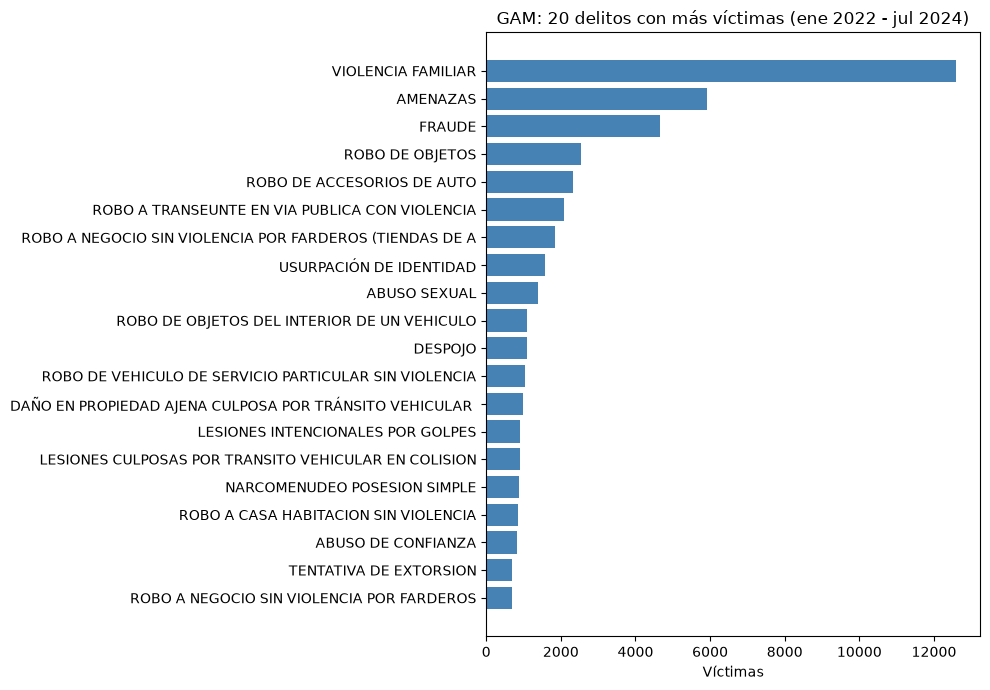

In [22]:
fig, ax = plt.subplots(figsize=(10, 7))
t20 = pareto.head(20).iloc[::-1]
ax.barh([d[:55] for d in t20.index], t20["victimas"], color="steelblue")
ax.set_title("GAM: 20 delitos con más víctimas (ene 2022 - jul 2024)")
ax.set_xlabel("Víctimas")
plt.tight_layout()
plt.show()

## 5 · Composición por bien jurídico: GAM vs CDMX
**Índice de especialización (IE)** = % del grupo en GAM ÷ % del grupo en la CDMX.
- IE > 1: el grupo pesa más en GAM que en la ciudad (GAM está "especializada" en ese delito).
- IE < 1: pesa menos.

`pct_de_la_ciudad` indica qué parte del total de la CDMX ocurre en GAM. Como referencia, GAM aporta ~10% de todas las víctimas.

In [23]:
comp = pd.DataFrame({
    "pct_GAM": gam["grupo"].value_counts(normalize=True) * 100,
    "pct_CDMX": delitos["grupo"].value_counts(normalize=True) * 100,
})
comp["IE"] = comp["pct_GAM"] / comp["pct_CDMX"]
comp["victimas_GAM"] = gam["grupo"].value_counts()
comp["pct_de_la_ciudad"] = comp["victimas_GAM"] / delitos["grupo"].value_counts() * 100
comp = comp.sort_values("IE", ascending=False).round(2)
comp

,pct_GAM,pct_CDMX,IE,victimas_GAM,pct_de_la_ciudad
grupo,,,,,
Contra la vida (dolosos),0.82,0.57,1.43,514,14.50
Familia,21.40,17.80,1.20,13422,12.22
Otros,1.10,0.95,1.16,692,11.75
Libertad y seguridad sexual,5.15,4.62,1.11,3230,11.32
"Narcomenudeo, armas y crimen organizado",2.11,1.98,1.07,1323,10.85
Libertad y seguridad personal,12.57,11.86,1.06,7886,10.77
Robo con violencia,7.49,7.28,1.03,4697,10.45
Integridad física (lesiones),2.42,2.36,1.03,1521,10.44
Culposos y tránsito,5.10,5.02,1.02,3201,10.34


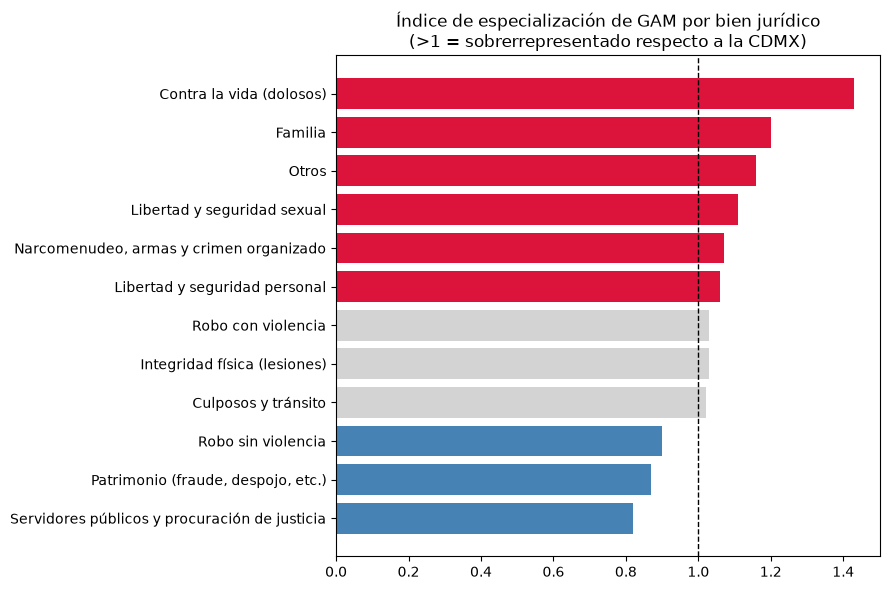

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
colores = ["crimson" if v > 1.05 else ("steelblue" if v < 0.95 else "lightgray") for v in comp["IE"]]
ax.barh(comp.index[::-1], comp["IE"][::-1], color=colores[::-1])
ax.axvline(1, color="black", ls="--", lw=1)
ax.set_title("Índice de especialización de GAM por bien jurídico\n(>1 = sobrerrepresentado respecto a la CDMX)")
plt.tight_layout()
plt.show()

## 6 · Gravedad: GAM vs CDMX

In [25]:
orden = ["Crítica", "Alta", "Media", "Baja"]
grav = pd.DataFrame({
    "victimas_GAM": gam["gravedad"].value_counts(),
    "pct_GAM": gam["gravedad"].value_counts(normalize=True) * 100,
    "pct_CDMX": delitos["gravedad"].value_counts(normalize=True) * 100,
}).loc[orden]
grav["IE"] = grav["pct_GAM"] / grav["pct_CDMX"]
grav["pct_de_la_ciudad"] = grav["victimas_GAM"] / delitos["gravedad"].value_counts() * 100
print(f"Alta + Crítica en GAM: {grav.loc[['Crítica','Alta'],'pct_GAM'].sum():.1f}%  |  CDMX: {grav.loc[['Crítica','Alta'],'pct_CDMX'].sum():.1f}%")
grav.round(2)

Alta + Crítica en GAM: 35.9%  |  CDMX: 31.4%


,victimas_GAM,pct_GAM,pct_CDMX,IE,pct_de_la_ciudad
gravedad,,,,,
Crítica,1492,2.38,2.13,1.12,11.36
Alta,21050,33.56,29.23,1.15,11.67
Media,32483,51.78,56.08,0.92,9.39
Baja,7706,12.28,12.56,0.98,9.94


### Contexto: delitos críticos y contra la vida por alcaldía
Se calculan totales y tasas anuales por 100 mil habitantes (Censo 2020) para ubicar a GAM.

In [26]:
poblacion = {
    "Iztapalapa": 1835486, "Gustavo A. Madero": 1173351, "Álvaro Obregón": 759137,
    "Tlalpan": 699928, "Coyoacán": 614447, "Cuauhtémoc": 545884,
    "Venustiano Carranza": 443704, "Xochimilco": 442178, "Benito Juárez": 434153,
    "Azcapotzalco": 432205, "Miguel Hidalgo": 414470, "Iztacalco": 404695,
    "Tláhuac": 392313, "La Magdalena Contreras": 247622,
    "Cuajimalpa de Morelos": 217686, "Milpa Alta": 152685,
}
pob = pd.Series(poblacion)
anual = MESES / 12

ctx = pd.DataFrame({
    "criticos": delitos[delitos["gravedad"] == "Crítica"].groupby("alcaldia_catalogo").size(),
    "vida_dolosos": delitos[delitos["grupo"] == "Contra la vida (dolosos)"].groupby("alcaldia_catalogo").size(),
})
ctx["tasa_criticos"] = ctx["criticos"] / anual / pob * 1e5
ctx["tasa_vida"] = ctx["vida_dolosos"] / anual / pob * 1e5
ctx["rank_vida_total"] = ctx["vida_dolosos"].rank(ascending=False).astype(int)
ctx["rank_vida_tasa"] = ctx["tasa_vida"].rank(ascending=False).astype(int)
print(f"Promedio CDMX — tasa críticos: {ctx['criticos'].sum()/anual/pob.sum()*1e5:.1f} | tasa vida: {ctx['vida_dolosos'].sum()/anual/pob.sum()*1e5:.1f}")
ctx.sort_values("vida_dolosos", ascending=False).round(1)

Promedio CDMX — tasa críticos: 55.2 | tasa vida: 14.9


,criticos,vida_dolosos,tasa_criticos,tasa_vida,rank_vida_total,rank_vida_tasa
alcaldia_catalogo,,,,,,
Iztapalapa,2623,729,55.3,15.4,1,7
Gustavo A. Madero,1492,514,49.2,17.0,2,6
Cuauhtémoc,2299,427,163.0,30.3,3,1
Álvaro Obregón,857,261,43.7,13.3,4,9
Venustiano Carranza,735,250,64.1,21.8,5,2
Tlalpan,933,239,51.6,13.2,6,11
Tláhuac,595,198,58.7,19.5,7,3
Xochimilco,612,198,53.6,17.3,7,4
Azcapotzalco,427,152,38.2,13.6,9,8


## 7 · Delitos específicos sobrerrepresentados en GAM
IE por delito, solo para delitos con al menos 100 víctimas en GAM (para evitar índices inestables por pocos casos).

In [27]:
ie = pd.DataFrame({
    "victimas_GAM": gam["delito"].value_counts(),
    "pct_GAM": gam["delito"].value_counts(normalize=True) * 100,
    "pct_CDMX": delitos["delito"].value_counts(normalize=True) * 100,
}).dropna()
ie["IE"] = ie["pct_GAM"] / ie["pct_CDMX"]
ie["gravedad"] = ie.index.map(catalogo["gravedad"])
ie = ie[ie["victimas_GAM"] >= 100].sort_values("IE", ascending=False).round(2)
print("Más sobrerrepresentados en GAM:")
ie.head(15)

Más sobrerrepresentados en GAM:


,victimas_GAM,pct_GAM,pct_CDMX,IE,gravedad
delito,,,,,
ROBO DE VEHICULO DE SERVICIO PARTICULAR CON VIOLENCIA,546.0,0.87,0.45,1.95,Alta
ROBO DE OBJETOS A ESCUELA,139.0,0.22,0.12,1.83,Media
USO DE DOCUMENTO FALSO,134.0,0.21,0.12,1.75,Baja
ROBO A NEGOCIO SIN VIOLENCIA POR FARDEROS (TIENDAS DE AUTOSERVICIO),1835.0,2.93,1.76,1.67,Media
ATAQUE A LAS VIAS GENERALES DE COMUNICACIÓN,289.0,0.46,0.28,1.66,Baja
ROBO DE VEHICULO DE SERVICIO PARTICULAR SIN VIOLENCIA,1027.0,1.64,1.06,1.55,Media
HOMICIDIO POR ARMA DE FUEGO,308.0,0.49,0.32,1.54,Crítica
ENCUBRIMIENTO,387.0,0.62,0.41,1.51,Baja
ROBO A PASAJERO A BORDO DE METROBUS SIN VIOLENCIA,160.0,0.26,0.17,1.46,Media


In [28]:
print("Menos representados en GAM:")
ie.tail(8)

Menos representados en GAM:


,victimas_GAM,pct_GAM,pct_CDMX,IE,gravedad
delito,,,,,
ABUSO DE CONFIANZA,813.0,1.30,1.86,0.70,Media
ROBO DE DINERO,103.0,0.16,0.24,0.69,Media
ROBO DE PLACA DE AUTOMOVIL,310.0,0.49,0.72,0.69,Media
"PRODUCCIÓN, IMPRESIÓN, ENAJENACIÓN, DISTRIBUCIÓN, ALTERACIÓN O FALSIFICACIÓN DE TÍTULOS AL PORTADOR, DOCUMENTOS DE CRÉDITO PÚBLICOS O VALES DE CANJE",214.0,0.34,0.51,0.66,Baja
ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA,204.0,0.33,0.51,0.63,Alta
ROBO DE OBJETOS DEL INTERIOR DE UN VEHICULO,1100.0,1.75,2.87,0.61,Media
ROBO A TRANSEUNTE EN PARQUES Y MERCADOS CON VIOLENCIA,211.0,0.34,0.63,0.54,Alta
ROBO DE VEHICULO DE PEDALES,185.0,0.29,0.66,0.45,Media


## 8 · Proporción de robos con violencia

In [29]:
def pct_violento(df):
    robos = df[df["grupo"].str.startswith("Robo")]
    return (robos["grupo"] == "Robo con violencia").mean() * 100

print(f"Robos con violencia — GAM: {pct_violento(gam):.1f}%  |  CDMX: {pct_violento(delitos):.1f}%")

Robos con violencia — GAM: 25.1%  |  CDMX: 22.6%


## 9 · Interpretación
1. **Perfil orientado a delitos contra las personas.** Los grupos sobrerrepresentados en GAM son *Contra la vida* (IE ≈ 1.43), *Familia* (≈ 1.20) y *Libertad sexual* (≈ 1.11); los subrepresentados son patrimoniales (fraude, robo sin violencia). GAM aporta ~10% de las víctimas de la ciudad, pero **~14.5% de las víctimas de delitos dolosos contra la vida**.
2. **Violencia familiar es el delito principal**: 1 de cada 5 víctimas en GAM (IE ≈ 1.22).
3. **Mayor gravedad relativa:** ~36% de las víctimas de GAM sufren delitos de gravedad Alta o Crítica, contra ~31% en la CDMX.
4. **Delitos específicos destacados:** robo de vehículo con violencia (IE ≈ 1.95), homicidio por arma de fuego (≈ 1.54), violación (≈ 1.29).
5. **Matiz honesto:** en *tasa* por habitante de delitos críticos GAM está cerca del promedio; su relevancia viene de combinar **volumen absoluto alto** (2.ª en víctimas contra la vida) con un **perfil cargado hacia violencia contra las personas**.